# Retail Rocket Product Analytics Case Study:

Although the platform receives a large volume of user activity, not every visitor completes a purchase. Understanding where users drop off, how customer behavior changes over time, and which customer segments contribute the most value is the main goal of this analysis.

a few business questions this analysis aims to answer are:

1. How efficient is the platform based on key product metrics?
2. Where do users abandon the purchase journey?
3. Are newly acquired users returning over time?
4. Which customer segments generate the highest value?
5. What factors may be contributing to lower conversions?
6. What product and business recommendations can improve conversion and retention?

#

### 1. Data Auditing

In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 


In [2]:
category_tree= pd.read_csv(r"C:\Users\Pavni Rastogi\Downloads\product-analytics-files\category_tree.csv")
events= pd.read_csv(r"C:\Users\Pavni Rastogi\Downloads\product-analytics-files\events.csv")
item_properties_1= pd.read_csv(r"C:\Users\Pavni Rastogi\Downloads\product-analytics-files\item_properties_part1.csv")
item_properties_2= pd.read_csv(r"C:\Users\Pavni Rastogi\Downloads\product-analytics-files\item_properties_part2.csv")

In [5]:
dfs= [category_tree, events, item_properties_1, item_properties_2]
for i in dfs:
    print(i.head())
    print()

   categoryid  parentid
0        1016     213.0
1         809     169.0
2         570       9.0
3        1691     885.0
4         536    1691.0

       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN
1  1433224214164     992329  view  248676            NaN
2  1433221999827     111016  view  318965            NaN
3  1433221955914     483717  view  253185            NaN
4  1433221337106     951259  view  367447            NaN

       timestamp  itemid    property                            value
0  1435460400000  460429  categoryid                             1338
1  1441508400000  206783         888          1116713 960601 n277.200
2  1439089200000  395014         400  n552.000 639502 n720.000 424566
3  1431226800000   59481         790                       n15360.000
4  1431831600000  156781         917                           828513

       timestamp  itemid property            value
0  1433041200000  183478      561       

events dataframe will have more relevant usecase. 

category tree us product category hierarchy, useful for product categorisation. 

item_properties include attributes of products such as itemid, categoryid, value and timestamp. 

In [ ]:
datasets = {"category_tree": category_tree, "events": events, "item_properties_1": item_properties_1, "item_properties_2": item_properties_2}
for name,df in datasets.items():
    print(name, df.shape)
    print()

category_tree (1669, 2)

events (2756101, 5)

item_properties_1 (10999999, 4)

item_properties_2 (9275903, 4)



category_tree: 2 columns, 1669 rows

events: 5 columns, 2.7 Million rows

item_properties_1: 4 columns, 10.9 Million rows 

item_properties_2: 4 columns, 9.2 Million rows  = 20M rows combinec

In [14]:
datasets = {"category_tree": category_tree, "events": events, "item_properties_1": item_properties_1, "item_properties_2": item_properties_2}
for name,df in datasets.items():
    print(name, df.info())
    print()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1669 entries, 0 to 1668
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   categoryid  1669 non-null   int64  
 1   parentid    1644 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 26.2 KB
category_tree None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          object 
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), object(1)
memory usage: 105.1+ MB
events None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10999999 entries, 0 to 10999998
Data columns (total 4 columns):
 #   Column     Dtype 
---  ------     ----- 
 0   timestamp  int64 
 1   itemid     int64 
 2   property   object
 3   value      object
dtypes: int64(2), obje

timestamps dtype needs to be changed

In [15]:
#checking what properties actually exist in item_properties:

item_properties = pd.concat([item_properties_1, item_properties_2], ignore_index=True)
item_properties['property'].value_counts().head(30)

property
888           3000398
790           1790516
available     1503639
categoryid     788214
6              631471
283            597419
776            574220
678            481966
364            476486
202            448938
839            417239
917            417227
764            417053
159            417053
112            417053
227            347492
698            289849
451            264416
663            240813
962            239372
400            216481
689            214225
28             172393
928            160818
1036           146246
810            142575
348            113303
544            113246
713            104931
1032            82805
Name: count, dtype: int64

The item_properties dataset contains anonymized product properties. Only categoryid and available are understandable and suitable for business analysis. The remaining property identifiers lack information, so they will be excluded from further analysis.

In [ ]:
#assessing data quality:

#nulls:
for name, df in datasets.items():
    print(name)
    print(df.isnull().sum())
    print()



category_tree
categoryid     0
parentid      25
dtype: int64

events
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

item_properties_1
timestamp    0
itemid       0
property     0
value        0
dtype: int64

item_properties_2
timestamp    0
itemid       0
property     0
value        0
dtype: int64



- parentid contains 25 null values which represent root categories. 
- nulls in transaction id are for interactions that didn't result in transactions. 
- hence, no action needed to be performed on nulls. 


In [18]:
#duplicate rows:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()}")

category_tree: 0
events: 460
item_properties_1: 0
item_properties_2: 0


In [19]:
#unique values in events:
events.nunique()

timestamp        2750455
visitorid        1407580
event                  3
itemid            235061
transactionid      17672
dtype: int64

so there are around 235k (2.35 lakh) products, 1.4M users and 17.6k transactions. 

In [27]:
events.groupby('event').size()

event
addtocart        69332
transaction      22457
view           2664312
dtype: int64

three events are happening: view, addtocart, transaction

In [28]:
events['event'].value_counts(normalize=True) * 100

event
view           96.669607
addtocart       2.515583
transaction     0.814810
Name: proportion, dtype: float64

- Product views are 96.67% of all recorded interactions, and only 0.81% are completed transactions. 

- This indicates that the vast majority of user interactions do not result in purchases.
- this makes conversion optimization a key area for further analysis.

In [29]:
events['transactionid'].notna().sum()

np.int64(22457)

out of 2.7M rows, only 22.4k have transaction id (not missing data, its stored only for filed transactions)

note: 460 rows are duplicates. 

In [31]:
#checking what type of events have duplicate rows:
events[events.duplicated()].event.value_counts()

event
addtocart    366
view          94
Name: count, dtype: int64

In [39]:
#checking duplicate rows
events[events.duplicated(keep=False)].sort_values(['timestamp', 'visitorid', 'itemid']).head(10)

,timestamp,visitorid,event,itemid,transactionid,datetime
1466550,1430639017006,771203,view,250578,NaN,2015-05-03 07:43:37.006
1471736,1430639017006,771203,view,250578,NaN,2015-05-03 07:43:37.006
1482986,1430780975099,234788,addtocart,33,NaN,2015-05-04 23:09:35.099
1496938,1430780975099,234788,addtocart,33,NaN,2015-05-04 23:09:35.099
1489030,1430788228572,594432,addtocart,311596,NaN,2015-05-05 01:10:28.572
1495975,1430788228572,594432,addtocart,311596,NaN,2015-05-05 01:10:28.572
1513411,1430851280377,882313,addtocart,168717,NaN,2015-05-05 18:41:20.377
1519889,1430851280377,882313,addtocart,168717,NaN,2015-05-05 18:41:20.377
1518734,1430863559288,734488,addtocart,351585,NaN,2015-05-05 22:05:59.288
1522559,1430863559288,734488,addtocart,351585,NaN,2015-05-05 22:05:59.288


- all are duplicate rows so dropping them

In [40]:
events.drop_duplicates(inplace=True)
events.duplicated().sum()

np.int64(0)

- converting timestamps to datetime format: adding another column

In [34]:
#converting timestamps to date-time format:
events['datetime'] = pd.to_datetime(events['timestamp'], unit='ms')
print(events['datetime'].dtype)

datetime64[ns]


In [35]:
#time-range:
print(events['datetime'].min())
print(events['datetime'].max())

2015-05-03 03:00:04.384000
2015-09-18 02:59:47.788000


3/may/2015 to 18/september/2015

approx 4 months of data

In [48]:
#combining item_properties_1 and item_properties_2:
item_properties = pd.concat([item_properties_1, item_properties_2],ignore_index=True)
print(item_properties.shape)

(20275902, 4)


#

#### Data Audit and Cleaning summary:

- missing columns: parent id, transaction id, both are expected and fine observations. 

- 460 duplicate rows in events data, dropped. 
- timestamp in unix milliseconds changed to datetime column. 
- the time duration of dataset is from 3 May 2015 to 18 Sep 2015, approximately 4.5 months.



### Feature Engineering

creating mainly date-time related features for ease of grouping and understanding activity distribution, timelines.

- date, year, month
- month-name, day
- whether its a weekday/weekend? so weekday & weekend columns
- (weekday column contains weekday name; weekend column is a boolean)
- also hourly distinction

In [42]:
events['date'] = events['datetime'].dt.date
events['year'] = events['datetime'].dt.year
events['month'] = events['datetime'].dt.month
events['month_name'] = events['datetime'].dt.month_name()
events['day'] = events['datetime'].dt.day
events['weekday'] = events['datetime'].dt.day_name()
events['hour'] = events['datetime'].dt.hour
events['is_weekend'] = events['weekday'].isin(['saturday', 'sunday'])

In [43]:
events.head()

,timestamp,visitorid,event,itemid,transactionid,datetime,date,year,month,month_name,day,weekday,hour,is_weekend
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117,2015-06-02,2015,6,June,2,Tuesday,5,False
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164,2015-06-02,2015,6,June,2,Tuesday,5,False
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827,2015-06-02,2015,6,June,2,Tuesday,5,False
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914,2015-06-02,2015,6,June,2,Tuesday,5,False
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106,2015-06-02,2015,6,June,2,Tuesday,5,False


#

### Exploratory Data Analysis (EDA)

*OVERALL ACTIVITY*

In [ ]:
print("total unique users are: ", events['visitorid'].nunique())
print("total events are: ", events['event'].count())
print("products involved in events are: ", events['itemid'].nunique())
print("total products in catalog are: ", item_properties['itemid'].nunique())


total unique users are:  1407580
total events are:  2755641
products involved in events are:  235061
total products in catalog are:  417053
total events:  2755641


- out of the 417k products available in the catalog, 235k (56.4%) received at least one user interaction during the time period.
- his suggests that a good portion of the catalog remained inactive, indicating a highly skewed distribution of customer attention.

#

*TIME BASED TRENDS*

1. Date vs events and Date vs transactions

In [151]:
#daily activity:
daily_events = (events.groupby("date").size().reset_index(name="events"))
#daily_events.head()

In [152]:
#daily transactions:
daily_transactions=(events.groupby("date")['transactionid'].nunique().reset_index(name="transactions"))
#daily_transactions.head()

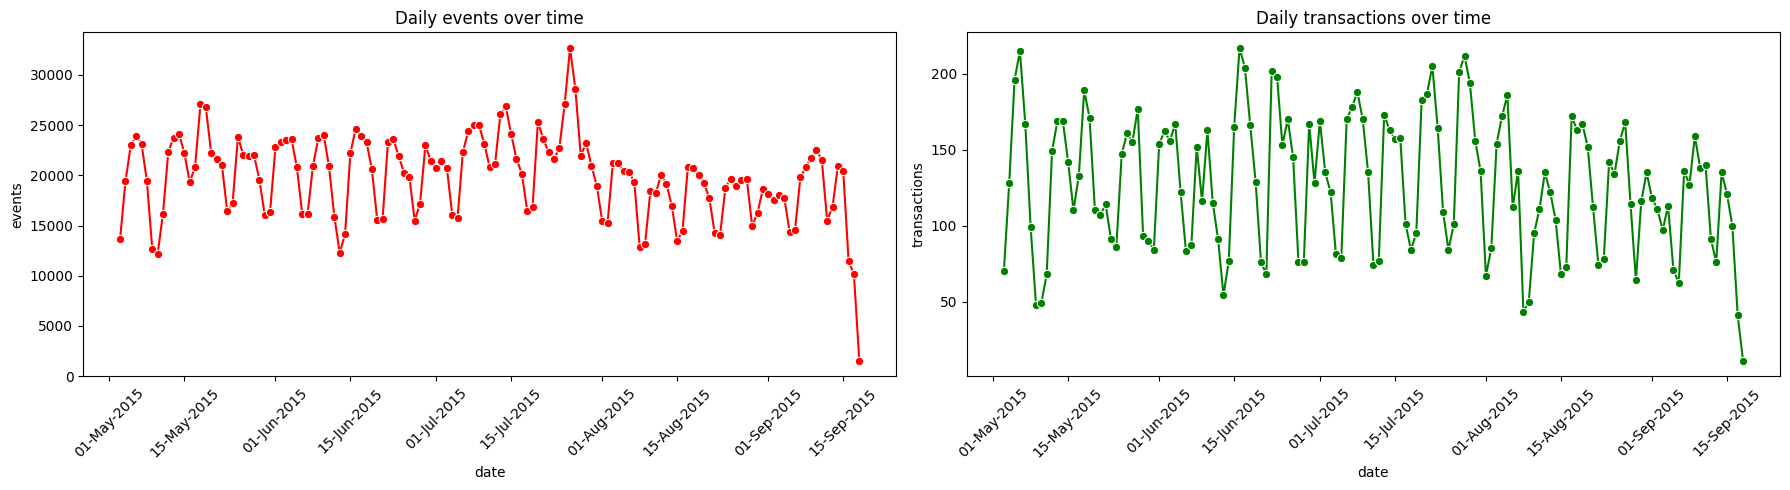

In [153]:
#visulaising date vs events and date vs transactions:
import matplotlib.dates as mdates
fig, axes = plt.subplots(1, 2, figsize=(18, 5))

sns.lineplot(x='date', y='events', data=daily_events, marker='o', color='red', ax=axes[0])
axes[0].set_title("Daily events over time")
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b-%Y'))
axes[0].tick_params(axis='x', rotation=45)

sns.lineplot(x='date', y='transactions', data=daily_transactions, marker='o', color='green', ax=axes[1])
axes[1].set_title("Daily transactions over time")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d-%b-%Y'))
axes[1].tick_params(axis='x', rotation=45)  
plt.tight_layout()



**Daily events over time**
- the pattern in events vs dates look periodic, user engagement likely varies by weekdays in a particular pattern. can be investigated further.
- there's noticeable spike in events towards july end. maybe due to seasonal demands, marketing campaign etc.

**Daily transactions over time**
- Daily transactions over time also show similar weekly pattern as overall events/activities, hence purchase behaviour is similar to user engagement behaviour.
- noe that, transactions are on a lower scale as compared to daily user engagement which is quite usual for the dataset.
- note: the final day's sharp decline is due to the dataset ending mid-day rather than an actual drop in sales.
- also, high engagement days also produce proportionally higher purchases, or whether these conversion rates differ independently of traffic. can explore into this further. 

#

2. Weekdays vs events and Weekdays vs transactions

In [160]:
#weekday vs events 
events_weekday= events.groupby("weekday").size().reset_index(name="events")
#events_weekday

In [161]:
#weekdays vs transactions
transactions_weekday= events.groupby("weekday")['transactionid'].nunique().reset_index(name="transactions")
#transactions_weekday

view to purchase ratio

In [192]:
view_purchase_ratio=(events.groupby("weekday").agg(views=("visitorid", "count"),purchases=("transactionid", "count")))
view_purchase_ratio["view-purchase-ratio"]=round((view_purchase_ratio['purchases']/view_purchase_ratio['views'])*100, 2)
view_purchase_ratio

,views,purchases,view-purchase-ratio
weekday,,,
Friday,379624,2929,0.77
Monday,439738,3848,0.88
Saturday,305167,1811,0.59
Sunday,334375,1995,0.60
Thursday,418672,3750,0.90
Tuesday,447006,3973,0.89
Wednesday,431059,4151,0.96


(will be analysed further through funnel analysis)

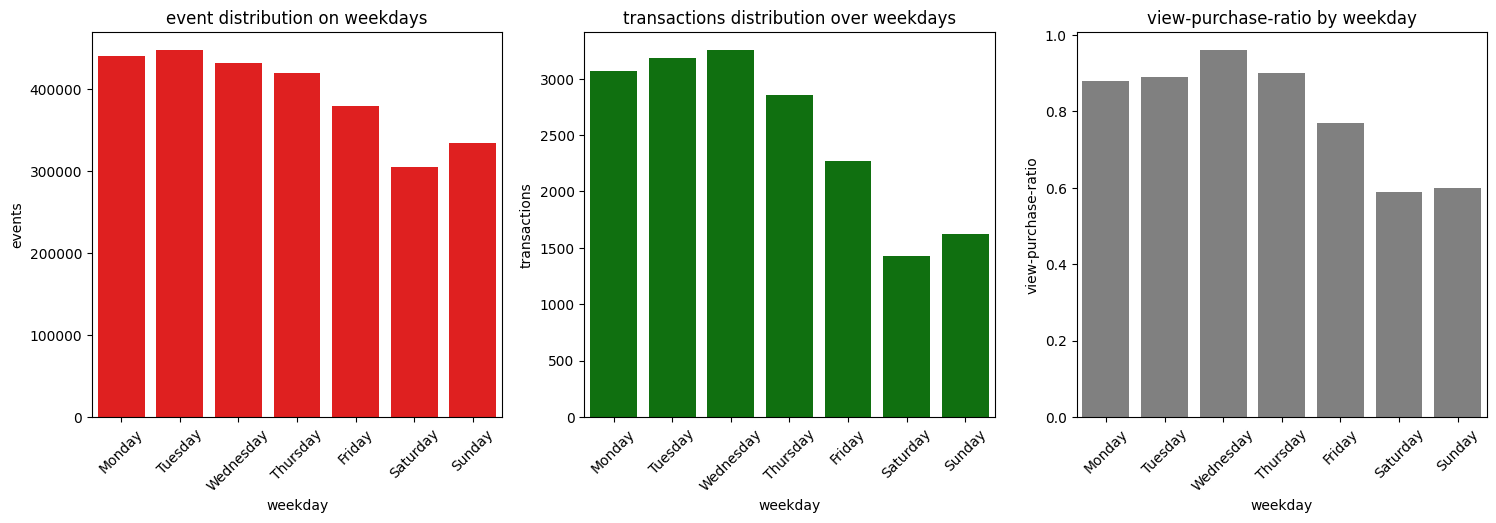

In [193]:
fig, axis = plt.subplots(1, 3, figsize=(18, 5))
weekday_order= ["Monday", "Tuesday", "Wednesday","Thursday", "Friday", "Saturday", "Sunday"]
sns.barplot(data=events_weekday,x="weekday",y="events", order=weekday_order, color='red', ax=axis[0])
axis[0].set_title("event distribution on weekdays")
axis[0].tick_params(axis='x', rotation=45)

sns.barplot(data=transactions_weekday,x="weekday",y="transactions", order=weekday_order, color='green', ax=axis[1])
axis[1].set_title("transactions distribution over weekdays")
axis[1].tick_params(axis='x', rotation=45)

sns.barplot(x='weekday', y='view-purchase-ratio', data=view_purchase_ratio, order=weekday_order, color='grey', ax=axis[2])
axis[2].set_title("view-purchase-ratio by weekday")
axis[2].tick_params(axis='x', rotation=45)

plt.show()

**observations:**

- User activity peaks during the middle of the workweek (Tuesday-Wednesday) and gradually declines toward the weekend, lowest at saturday.

- Transactions follows a nearly identical weekday pattern, indicating that purchase behavior closely matches with overall platform activity.

- The consistent decline in both events and transactions over the weekend suggests that reduced purchase volume is primarily driven by lower user traffic rather.

- cannot yet claim of its due to less conversion rates. 



#

3. daily hours vs events and daily hours vs transactions

In [165]:
#events by day hours:
hourly_events= events.groupby('hour').size().reset_index(name='events')
#hourly_events

In [166]:
#transactions by day hours:
hourly_transactions= events.groupby('hour')['transactionid'].nunique().reset_index(name='transactions')
#hourly_transactions

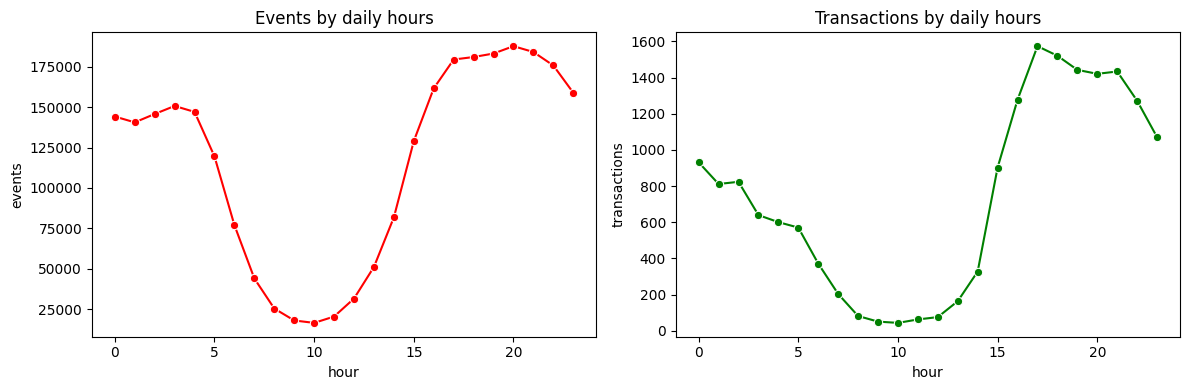

In [171]:
#visualising events by hours:
fig, axis= plt.subplots(1, 2, figsize=(12,4))
sns.lineplot(x='hour', y='events', data=hourly_events, marker='o', color='red', ax=axis[0])
axis[0].set_title("Events by daily hours")

sns.lineplot(x='hour', y='transactions', data=hourly_transactions, marker='o', color='green', ax=axis[1])
axis[1].set_title("Transactions by daily hours")
plt.tight_layout()
plt.show()

- user engagement and purchasing activity show strong alignment throughout the day. 
- both metrics reach their lowest levels during the morning hours(approximately 8 to 11 AM) and peak during the evening(7-9 PM), indicating that customers are significantly more active later in the day.

#

*PRODUCT BASED OBSERVATIONS*

top viewed products:

In [215]:
top_viewed=(events[events["event"]=="view"].groupby("itemid").size().sort_values(ascending=False).reset_index(name="views"))
top_10_viewed= top_viewed.head(10).sort_values("views", ascending=False)
#top_10_viewed


top added to cart products:

In [216]:
top_cart_prod=(events[events["event"]=="addtocart"].groupby("itemid").size().sort_values(ascending=False).head(10).reset_index(name="cart_additions"))
top_cart_prod= top_cart_prod.sort_values("cart_additions", ascending=False)
#top_cart_prod

top purchased products:

In [217]:
top_purchased=(events[events["event"]=="transaction"].groupby("itemid").size().sort_values(ascending=False).head(10).reset_index(name="purchases"))
top_purchased= top_purchased.sort_values("purchases", ascending= False)
#top_purchased

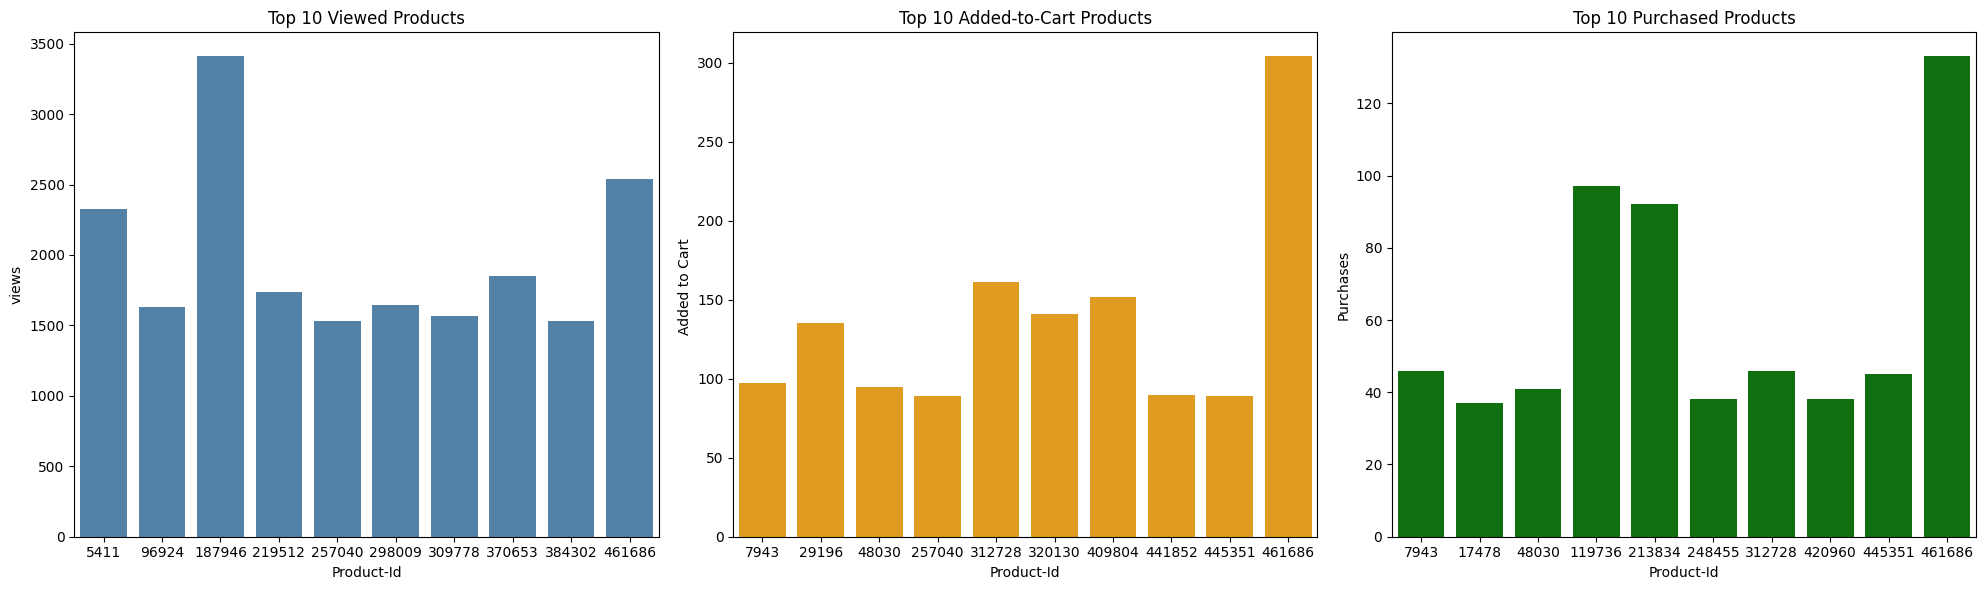

In [220]:
#visualising:
fig, axes= plt.subplots(1, 3, figsize=(20,6))

sns.barplot(x="itemid", y="views", data=top_10_viewed, ax=axes[0], color="steelblue")
axes[0].set_title("Top 10 Viewed Products")
axes[0].set_xlabel("Product-Id")
axes[0].set_ylabel("views")

sns.barplot(x="itemid", y="cart_additions",data=top_cart_prod, ax=axes[1], color="orange")
axes[1].set_title("Top 10 Added-to-Cart Products")
axes[1].set_xlabel("Product-Id")
axes[1].set_ylabel("Added to Cart ")

sns.barplot(x="itemid", y="purchases", data=top_purchased, ax=axes[2], color="green")
axes[2].set_title("Top 10 Purchased Products")
axes[2].set_xlabel("Product-Id")
axes[2].set_ylabel("Purchases")

plt.tight_layout()
plt.show()

**observations:**
- product *461686* is consistently among the most viewed, most added-to-cart, and most purchased products, indicating strong performance throughout the customer journey.

- several highly viewed products (like *187946*) do not appear among the most purchased items, suggesting potential drop-offs between product discovery and purchase.

- products such as *312728* and *7943* appear among the top purchased products despite not being among the most viewed, indicating relatively strong purchase intent once users discover them.

#

#### key observations from EDA:
- the platform recorded **2.76 million user interactions** across **1.4 million unique visitors** during a **4.5 month** observation period.
- user activity and purchases exhibit clear time based patterns, peaking during weekday evenings and declining over weekends.
- weekly transaction trends closely mirror overall engagement, suggesting that traffic volume is a major driver of sales.
- product popularity is highly concentrated, with only a small subset of products consistently dominating views, cart additions, and purchases.
- several popular products experience drop-offs before purchase, highlighting opportunities for further investigation during funnel and root cause analysis.

In [221]:
#exporting clean events dataframe:
events.to_csv("clean_events.csv", index=False)